# 噪声、权重与估计可信度

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

若前半组观测精确到0.1，后半组只能精确到1.0，等权拟合会给较差观测过多影响。权重的目的，是把不同可靠程度的信息放到同一尺度，而不是把“不喜欢的数据”随意压低。

## 独立误差的权重

假设$y=Ax_{\rm true}+\varepsilon$，且$\operatorname{Cov}(\varepsilon)=C=\operatorname{diag}(\sigma_i^2)$。加权目标是

$$F(x)=\frac12\sum_i\left(\frac{a_i^Tx-y_i}{\sigma_i}\right)^2.$$

权重为$w_i=1/\sigma_i^2$，实际缩放残差和设计矩阵时乘的是$\sqrt{w_i}=1/\sigma_i$。若误差是独立高斯，这同时是最大似然估计；高斯假设不是“能用最小二乘”的必要条件。

OLS: [1.02546 1.97647] WLS: [1.12019 1.90625]


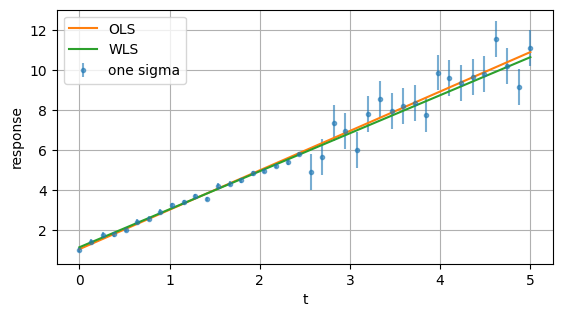

In [2]:
rng = np.random.default_rng(105)
t = np.linspace(0, 5, 40); A = np.column_stack([np.ones_like(t), t])
sigma = np.where(t < 2.5, .12, .9)
truth = np.array([1., 2.]); y = A@truth+rng.normal(size=len(t))*sigma
x_ols = np.linalg.lstsq(A, y, rcond=None)[0]
Aw, yw = A/sigma[:, None], y/sigma
x_wls = np.linalg.lstsq(Aw, yw, rcond=None)[0]
print('OLS:', x_ols, 'WLS:', x_wls)
plt.errorbar(t, y, yerr=sigma, fmt='.', alpha=.6, label='one sigma')
plt.plot(t, A@x_ols, label='OLS'); plt.plot(t, A@x_wls, label='WLS')
plt.xlabel('t'); plt.ylabel('response'); plt.legend(); plt.show()

## 相关误差需要整体白化

一般正定协方差$C=LL^T$，令$\tilde A=L^{-1}A$、$\tilde y=L^{-1}y$。用三角求解得到它们，再做普通最小二乘。因为

$$\|L^{-1}(Ax-y)\|^2=(Ax-y)^TC^{-1}(Ax-y),$$

这个方向必须是$L^{-1}$，不能误用$L^{-T}$。实现中无需形成$C^{-1}$。

## 参数的不确定性

满列秩、线性模型正确且$C$确知时，参数协方差为

$$\operatorname{Cov}(\hat x)=(A^TC^{-1}A)^{-1}.$$

若只知道共同的未知噪声尺度$\sigma^2$，通常用$\hat\sigma^2=\|r\|^2/(m-n)$估计，要求$m>n$且模型满秩。不要对已知绝对噪声的情况再次无条件乘这个尺度。

predicted standard errors: [0.04918 0.03276]
Monte Carlo standard errors: [0.04694 0.03247]


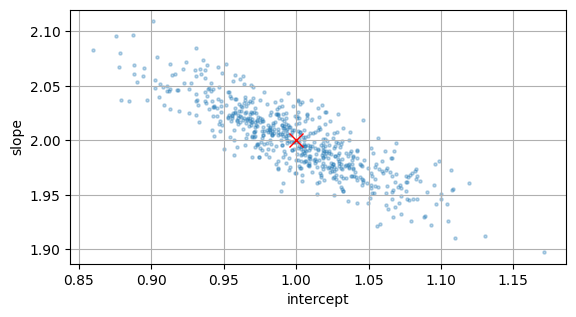

In [3]:
C = np.diag(sigma**2)
Aw2, yw2 = whiten(A, y, C)
assert np.allclose(Aw2, Aw)
cov_x = np.linalg.solve(Aw.T@Aw, np.eye(2))
draws = np.array([np.linalg.lstsq(Aw, (A@truth+rng.normal(size=len(t))*sigma)/sigma,
                 rcond=None)[0] for _ in range(600)])
print('predicted standard errors:', np.sqrt(np.diag(cov_x)))
print('Monte Carlo standard errors:', draws.std(axis=0, ddof=1))
plt.scatter(draws[:, 0], draws[:, 1], s=5, alpha=.3)
plt.plot(*truth, 'rx', markersize=10); plt.xlabel('intercept'); plt.ylabel('slope')
plt.show()

散点云的倾斜表示参数误差相关。斜率稍大、截距稍小，可能仍拟合同一批数据。每个参数的单独误差条不能完整描述这种关系。

正态近似下，已知协方差时可用$\hat x_j\pm1.96\,\mathrm{SE}_j$给出边际95%区间；未知尺度、线性高斯模型下应使用自由度$m-n$的$t$分布。非线性、边界或弱可辨识问题中，这些区间可能很不准确。

## 练习与解答

练习：所有标准差乘2，估计值和协方差如何改变？解答：所有权重统一除4，最优参数不变，参数协方差乘4，标准误乘2。

练习：两个完全相同且噪声完全相关的观测，是否提供双倍信息？解答：不是，完全相关时协方差奇异，不能直接使用本章正定白化。应合并观测或明确处理其有效子空间。

练习：用600次仿真的单次结果要求误差标准差与理论值完全相等，合理吗？解答：不合理；蒙特卡洛估计本身有采样误差，应随仿真次数增加检查趋势。